# Hydrogen author-matched run: Stage 2 at 200,000 epochs

- **Data:** `chemkan/data/generated/hydrogen.npz`: 36 Cantera conditions (T0 950-1200 K in 50 K steps x phi 0.5-1.5 in 0.2 steps), 35 for training and the held-out condition T0 1150 K, phi 1.3; 100 observation times over 0.6 ms. Stage 1 takes the observed temperature from `hydrogen_temperature_20000.npz` (dense Cantera temperature, 20,000 points).
- **Trainer:** `chemkan/scripts/combustion/train_combustion.py`, seed 0, on the Mac: 344-parameter ChemKAN, Adam lr 2e-3, Tsit5 rtol 1e-6 / atol 1e-8, batched float32 solves, direct autograd, t_ref = 6e-4 s (the RHS is divided by the time window), PINN weight 1e-4, no warm-up.
- **Runs:** Stage 1 `main/S1_seed0` (100,000 epochs). Stage 2 from its epoch-100,000 archive: `main/S2_seed0` (100,000 epochs), continued without changes to 150,000 (`main/S2_seed0_150k`) and 200,000 (`main/S2_seed0_200k`); each continuation is a copy of the previous run resumed from its last checkpoint (same optimizer state), so the earlier runs stay untouched.
- **Losses:** time-averaged MSE in normalized coordinates (Eq. 18 divided by the 100 time points). Training losses: the last epoch and the median over the last 1,000 epochs. One seed: differences between models are single-run observations.

In [1]:
%matplotlib inline
import csv
import json
import statistics
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "chemkan/scripts/figures"))
import fig07_hydrogen_trajectories as fig07
import fig08_hydrogen_generalization as fig08a
import fig08_hydrogen_ignition as fig08b

PY = sys.executable
SCRIPTS = ROOT / "chemkan/scripts"
MAIN = ROOT / "results/hydrogen"
RUNS = {"100k": MAIN / "S2_seed0", "150k": MAIN / "S2_seed0_150k", "200k": MAIN / "S2_seed0_200k"}
LAST = "200k"
FIGURES, TABLES, EVAL = MAIN / "figures", MAIN / "tables", MAIN / "eval"
for d in (FIGURES, TABLES, EVAL):
    d.mkdir(exist_ok=True)
for name, d in RUNS.items():
    print(f"{name}: {d.relative_to(ROOT)}  final checkpoint: {(d / 'stage2_final.pt').exists()}")

100k: results/experiments/hydrogen/author_matched/main/S2_seed0  final checkpoint: True
150k: results/experiments/hydrogen/author_matched/main/S2_seed0_150k  final checkpoint: True
200k: results/experiments/hydrogen/author_matched/main/S2_seed0_200k  final checkpoint: True


## Training losses

Stage 1 (`S1_seed0`) and Stage 2 from `S2_seed0_200k/stage2_history.csv`, which covers all 200,000 epochs (the 100k and 150k runs are its first rows; `main/README.md`). Grey: every epoch; blue: median over the previous 1,000 epochs. Dashed lines mark where the 100k and 150k runs ended.

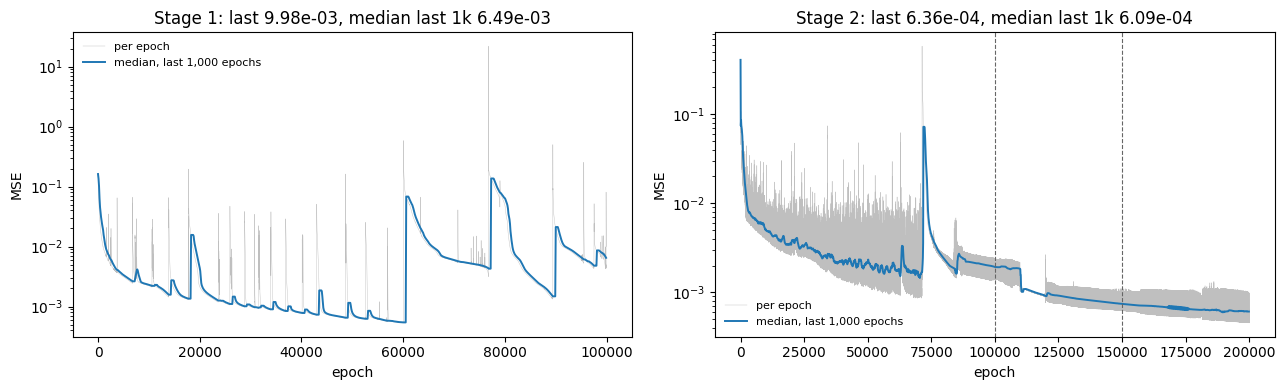

,epochs,last epoch,"median last 1,000",lowest,lowest at epoch
Stage-2 run,,,,,
100k,100000,1.388e-03,1.928e-03,8.585e-04,69660
150k,150000,7.425e-04,7.432e-04,6.212e-04,149887
200k,200000,6.360e-04,6.088e-04,4.548e-04,199954


In [2]:
def history(run_dir, name):
    rows = list(csv.DictReader(open(run_dir / name)))
    return (np.array([int(r["epoch"]) for r in rows]),
            np.array([float(r["mse_time_avg"]) for r in rows]))


def window_median(v, w=1000, step=100):
    idx = np.arange(0, len(v), step)
    return idx, np.array([np.median(v[max(0, i - w + 1):i + 1]) for i in idx])


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (title, run_dir, name) in zip(axes, [("Stage 1", MAIN / "S1_seed0", "stage1_history.csv"),
                                            ("Stage 2", RUNS[LAST], "stage2_history.csv")]):
    e, v = history(run_dir, name)
    idx, med = window_median(v)
    ax.semilogy(e, v, lw=0.3, color="0.75", label="per epoch")
    ax.semilogy(e[idx], med, lw=1.4, color="tab:blue", label="median, last 1,000 epochs")
    if title == "Stage 2":
        for x in (100_000, 150_000):
            ax.axvline(x, ls="--", lw=0.8, color="0.4")
    ax.set_title(f"{title}: last {v[-1]:.2e}, median last 1k {np.median(v[-1000:]):.2e}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE")
    ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "loss_curves_stage1_stage2_200k.png", dpi=150)
plt.show()

# The 100k and 150k runs' histories are the first 100,000 / 150,000 rows of the 200k file
# (main/README.md), so each run's numbers are read from that file up to its last epoch.
e, v = history(RUNS[LAST], "stage2_history.csv")
rows = []
for name, n in (("100k", 100_000), ("150k", 150_000), ("200k", 200_000)):
    i = int(np.argmin(v[:n]))
    rows.append({"Stage-2 run": name, "epochs": n, "last epoch": v[n - 1],
                 "median last 1,000": float(np.median(v[n - 1000:n])),
                 "lowest": v[i], "lowest at epoch": int(e[i])})
display(pd.DataFrame(rows).set_index("Stage-2 run").style.format(
    {c: "{:.3e}" for c in ("last epoch", "median last 1,000", "lowest")}))

## Evaluation on all 36 conditions

`evaluate_checkpoint.py` integrates each final Stage-2 model from the initial states alone. Time-averaged MSE per condition, median over the 35 training conditions and the held-out one, and the Fig. 8B quantities on the paper's 30 igniting conditions (T0 >= 1000 K).

In [3]:
EVAL_FILES = {"100k": EVAL / "S2_seed0.json", "150k": EVAL / "S2_seed0_150k.json",
              "200k": EVAL / "S2_seed0_200k.json"}
for name, d in RUNS.items():
    out = EVAL_FILES[name]
    if not out.exists():
        subprocess.run([PY, str(SCRIPTS / "combustion/evaluate_checkpoint.py"),
                        "--checkpoint", str(d / "stage2_final.pt"), "--out", str(out)],
                       check=True, capture_output=True)

rows = []
for name in RUNS:
    res = json.load(open(EVAL_FILES[name]))
    conds = pd.DataFrame(res["conditions"])
    fig8b = res["summary"]["fig8b_30"]
    rows.append({"model": name,
                 "train median": conds.loc[conds.split == "train", "mse_time_avg"].median(),
                 "held-out (1150 K, 1.3)": conds.loc[conds.split == "test", "mse_time_avg"].iloc[0],
                 "failed integrations": res["summary"]["n_integration_failed"],
                 "median |delay error|": fig8b["median_abs_ignition_delay_relative_error"],
                 "median T rise model [K]": fig8b["median_predicted_temperature_rise_K"],
                 "median T rise reference [K]": fig8b["median_reference_temperature_rise_K"]})
display(pd.DataFrame(rows).set_index("model").style.format(
    {"train median": "{:.3e}", "held-out (1150 K, 1.3)": "{:.3e}", "median |delay error|": "{:.1%}",
     "median T rise model [K]": "{:.0f}", "median T rise reference [K]": "{:.0f}"}))

,train median,"held-out (1150 K, 1.3)",failed integrations,median |delay error|,median T rise model [K],median T rise reference [K]
model,,,,,,
100k,1.160e-03,8.170e-04,0,3.7%,1598,1581
150k,5.520e-04,4.526e-04,0,1.6%,1609,1581
200k,4.748e-04,3.507e-04,0,1.4%,1605,1581


## Fig. 7: trajectories at the paper's two conditions (200k model)

Training condition T0 1050 K, phi 0.9 and held-out condition T0 1150 K, phi 1.3, predicted from the initial state alone. Markers: Cantera at the 100 observation times; lines: ChemKAN on a 601-point grid. Species multipliers as printed in the paper's Fig. 7 labels.

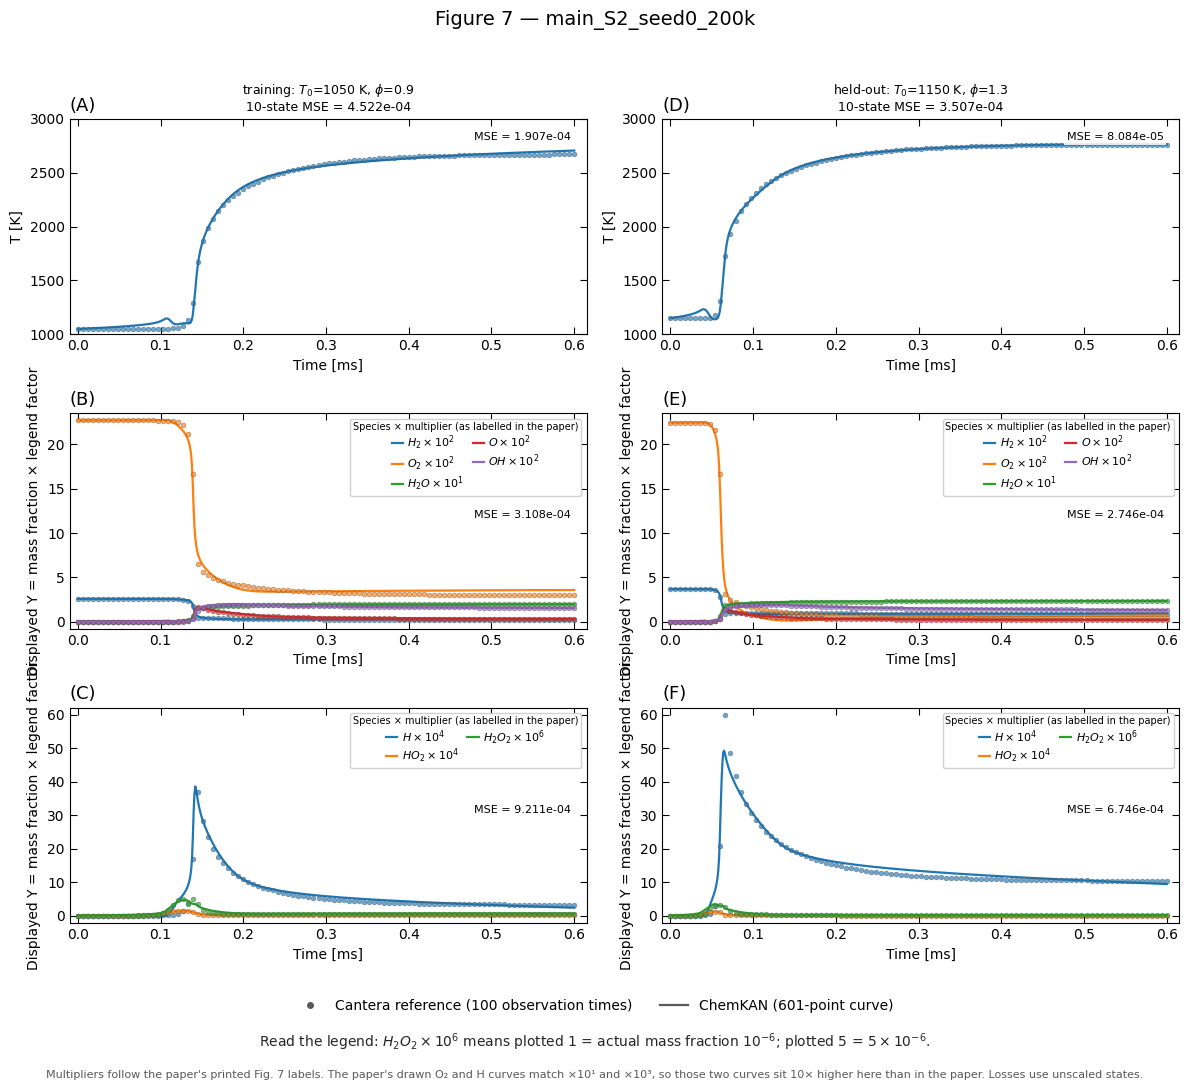

,condition,role,case_MSE_time_avg
0,1050/0.9,training,0.000452
1,1150/1.3,held-out,0.000351


In [4]:
figs, fig7 = fig07.make_figure(run_dirs={f"main_S2_seed0_{LAST}": RUNS[LAST]},
                               output_dir=FIGURES, table_path=TABLES / f"fig07_per_state_mse_{LAST}.csv",
                               time_averaged=True, show=True)
display(pd.DataFrame(fig7["rows"])[["condition", "role", "case_MSE_time_avg"]])

## Fig. 8A: generalization over 441 conditions (200k model)

`evaluate_hydrogen_grid.py` on `hydrogen_fine.npz` (21 x 21 conditions, T0 950-1200 K, phi 0.5-1.5, 100 time points), normalized with the training statistics of `hydrogen.npz`. Two colour ranges: the paper's 0-10 x 10^-4 and the full measured range (saved in `figures/fig08a_200k/`; `figures/fig08a_*` are the 100k model's).

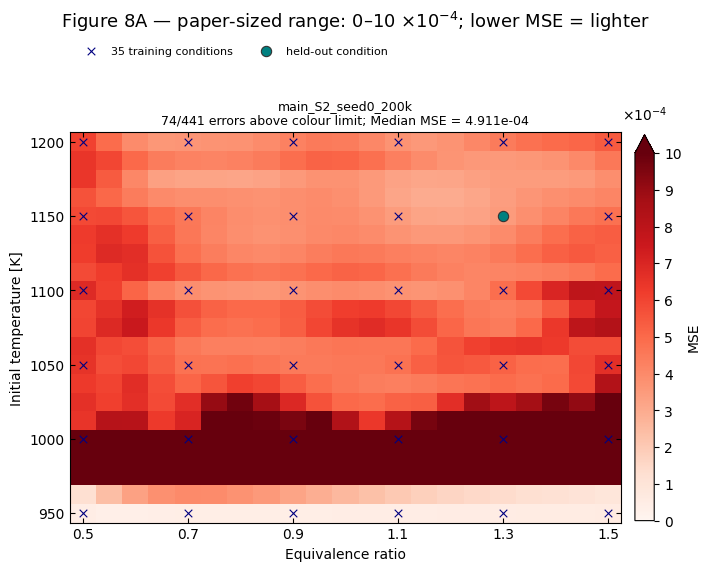

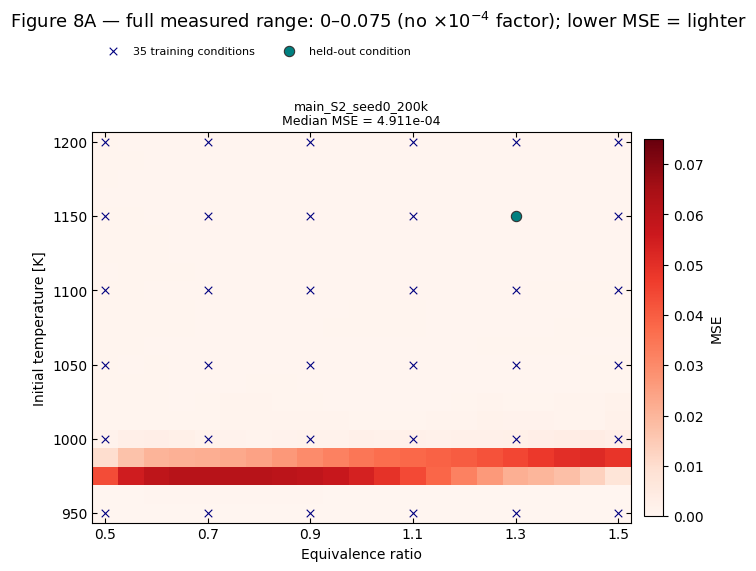

{'mse_time_avg': '4.160e-03', 'mse_time_avg_min': '3.834e-05', 'mse_time_avg_median': '4.911e-04', 'mse_time_avg_max': '6.115e-02'} | failed 0 / 441


In [5]:
label = f"main_S2_seed0_{LAST}"
subprocess.run([PY, "evaluate_hydrogen_grid.py", "--run-dir", str(RUNS[LAST]), "--out", str(TABLES),
                "--label", label, "--force"], cwd=SCRIPTS / "combustion", check=True, capture_output=True)
figs, grid = fig08a.make_figure(table_paths={label: TABLES / f"{label}_generalization_441.csv"},
                                output_dir=FIGURES / f"fig08a_{LAST}", time_averaged=True, show=True)
summary = json.load(open(TABLES / f"{label}_generalization_441.json"))
print({k: f"{summary[k]:.3e}" for k in ("mse_time_avg", "mse_time_avg_min", "mse_time_avg_median",
                                         "mse_time_avg_max")},
      f"| failed {summary['failed']} / {summary['conditions']}")

## Fig. 8B: ignition delay (200k model)

Delay = time of maximum dT/dt (paper Sec. III B), for the reference and the model on the same 601-point grid, on the paper's 30 igniting conditions. The panel title gives the median temperature rise of both, so a flat prediction cannot pass as an ignition.

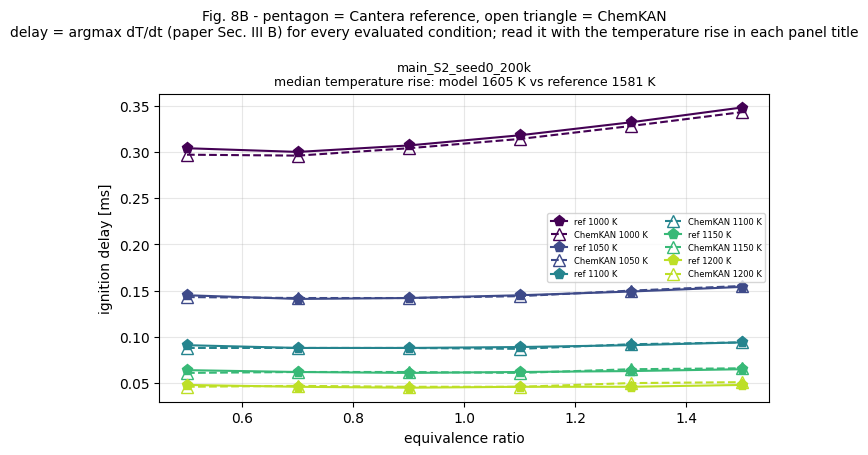

30 conditions | |relative delay error| median 1.4%, max 8.7% | median temperature rise: model 1605 K vs reference 1581 K


In [6]:
subprocess.run([PY, "evaluate_hydrogen_ignition.py", "--run-dir", str(RUNS[LAST]), "--out", str(TABLES),
                "--label", label, "--force"], cwd=SCRIPTS / "combustion", check=True, capture_output=True)
fig, ign = fig08b.make_figure(table_paths={label: TABLES / f"hydrogen_ignition_delay_{label}.csv"},
                              output_path=FIGURES / f"fig08b_hydrogen_ignition_delay_{LAST}", show=True)
s = ign[label]
print(f"{s['conditions']} conditions | |relative delay error| median {s['median_relative_error']:.1%}, "
      f"max {s['max_relative_error']:.1%} | median temperature rise: model "
      f"{s['median_model_temperature_rise_K']:.0f} K vs reference {s['median_reference_temperature_rise_K']:.0f} K")